# SECOM – Week 2: Baselines

Armand Bussolino, Aurélien Roche, Jérémie Leroy-Dubief

We evaluate two baselines and three cleaning variants of B1 with cross-validation on the training set.
The test set stays untouched until the final evaluation (Week 4).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # run from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.secom import load_secom, get_split
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (make_scorer, precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, average_precision_score)
from src.secom import make_pipeline, SEED

X, y = load_secom()
X_train, X_test, y_train, y_test = get_split(X, y)
print('Train:', X_train.shape, '| Fail:', int(y_train.sum()))
print('Test :', X_test.shape, '| Fail:', int(y_test.sum()), '-> kept for Week 4')

Train: (1253, 590) | Fail: 83
Test : (314, 590) | Fail: 21 -> kept for Week 4


## 1. Models

- **B0**: `DummyClassifier(strategy='prior')`, which always predicts Pass.
- **B1**: logistic regression with balanced class weights, after median imputation, removal of constant features and standardization.
- **B1 variants**: B1 with one extra cleaning step each (see notebook 02).

In [2]:
def logreg():
    return LogisticRegression(class_weight='balanced', max_iter=5000, random_state=SEED)

models = {
    'B0 Dummy': DummyClassifier(strategy='prior'),
    'B1 LogReg': make_pipeline(logreg()),
    'B1 + drop >50% missing': make_pipeline(logreg(), max_missing=0.5),
    'B1 + drop >50% missing + drop |r|>=0.98': make_pipeline(logreg(), max_missing=0.5, corr_threshold=0.98),
    'B1 + missing indicators': make_pipeline(logreg(), missing_indicator=True),
}

## 2. Cross-validation

Stratified 5-fold CV repeated 3 times (15 validation folds). Main metric: average precision (AP); random level = fail rate ≈ 0.066.
Recall, precision, F1 and balanced accuracy use the default 0.5 threshold, which is not tuned yet.

In [3]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
scoring = {'AP': 'average_precision', 'Recall': 'recall',
           'Precision': make_scorer(precision_score, zero_division=0),
           'F1': 'f1', 'Balanced acc.': 'balanced_accuracy'}

rows, ap_folds = [], {}
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    ap_folds[name] = s['test_AP']
    rows.append({'Model': name, **{m: f"{s['test_' + m].mean():.3f} ± {s['test_' + m].std():.3f}" for m in scoring}})
results = pd.DataFrame(rows).set_index('Model')
results

,AP,Recall,Precision,F1,Balanced acc.
Model,,,,,
B0 Dummy,0.066 ± 0.002,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
B1 LogReg,0.159 ± 0.063,0.264 ± 0.126,0.140 ± 0.062,0.182 ± 0.082,0.574 ± 0.065
B1 + drop >50% missing,0.161 ± 0.063,0.253 ± 0.124,0.138 ± 0.060,0.178 ± 0.080,0.571 ± 0.062
B1 + drop >50% missing + drop |r|>=0.98,0.159 ± 0.065,0.261 ± 0.136,0.139 ± 0.065,0.180 ± 0.086,0.574 ± 0.069
B1 + missing indicators,0.157 ± 0.054,0.265 ± 0.131,0.161 ± 0.070,0.196 ± 0.083,0.584 ± 0.061


Paired comparison with B1: AP difference on the same 15 folds.

In [4]:
base = ap_folds['B1 LogReg']
pd.DataFrame({name: {'mean AP diff': (ap - base).mean(), 'folds better than B1': f'{(ap > base).sum()}/15'}
              for name, ap in ap_folds.items() if name.startswith('B1 +')}).T.round(3)

,mean AP diff,folds better than B1
B1 + drop >50% missing,0.002426,8/15
B1 + drop >50% missing + drop |r|>=0.98,-0.000259,7/15
B1 + missing indicators,-0.001679,8/15


**Observations.** B1 clearly beats B0 on AP (more than twice the random level) but remains weak: at the 0.5 threshold it catches only about a quarter of the failures. The spread across folds is large because each fold has only about 17 failures. No cleaning variant changes AP beyond this noise (each beats B1 on about half of the folds), which matches notebook 02. B1 stays the baseline. The cleaning `max_missing=0.5, corr_threshold=0.98` is kept as an option for Week 3: same performance with about a third fewer features.

## 3. Errors and precision-recall trade-off

Out-of-fold predictions on the training set (5-fold CV): one prediction per training sample, made by a model that did not see it. This is **not** a test result.

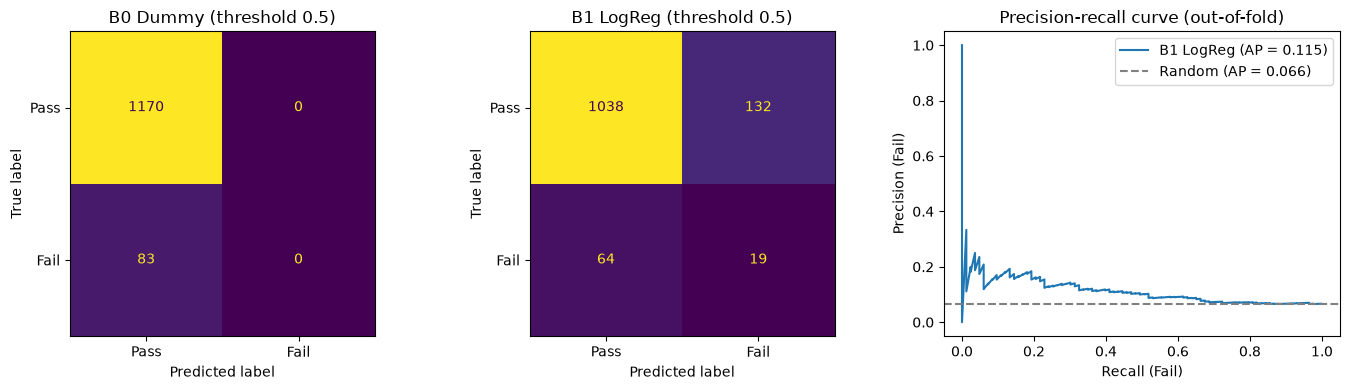

In [5]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = {name: cross_val_predict(models[name], X_train, y_train, cv=cv5, method='predict_proba')[:, 1]
       for name in ['B0 Dummy', 'B1 LogReg']}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes[:2], oof):
    cm = confusion_matrix(y_train, (oof[name] >= 0.5).astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['Pass', 'Fail']).plot(ax=ax, colorbar=False)
    ax.set_title(f'{name} (threshold 0.5)')

prec, rec, _ = precision_recall_curve(y_train, oof['B1 LogReg'])
axes[2].plot(rec, prec, label=f"B1 LogReg (AP = {average_precision_score(y_train, oof['B1 LogReg']):.3f})")
axes[2].axhline(y_train.mean(), color='gray', ls='--', label=f'Random (AP = {y_train.mean():.3f})')
axes[2].set_xlabel('Recall (Fail)'); axes[2].set_ylabel('Precision (Fail)')
axes[2].set_title('Precision-recall curve (out-of-fold)'); axes[2].legend()
plt.tight_layout(); plt.show()

What recall could B1 reach at other thresholds? This is only a preview: the threshold will be tuned in Week 3, inside the CV.

In [6]:
p = oof['B1 LogReg']
rows = []
for t in [0.5, 0.2, 0.1, 0.05, 0.01]:
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred, labels=[0, 1]).ravel()
    rows.append({'threshold': t, 'fails caught': f'{tp}/{tp + fn}', 'false alarms': fp,
                 'recall': tp / (tp + fn), 'precision': tp / max(tp + fp, 1)})
pd.DataFrame(rows).set_index('threshold').round(3)

,fails caught,false alarms,recall,precision
threshold,,,,
0.50,19/83,132,0.229,0.126
0.20,27/83,178,0.325,0.132
0.10,29/83,214,0.349,0.119
0.05,31/83,244,0.373,0.113
0.01,40/83,347,0.482,0.103


**Observations.** B0 never detects a failure. B1 catches some failures but with many false alarms. Lowering the threshold increases recall slowly while false alarms grow fast: the model's probabilities are extreme, a sign of overfitting (hundreds of features for 83 failures). The 60% recall target (O3) is out of reach for B1.

## 4. Summary for Week 3

- **Reference to beat:** B1 CV AP (table above), random level ≈ 0.066. The test set is still untouched.
- **Main issue:** overfitting. Next steps: stronger regularization (tune C, L1 penalty) and feature selection (filter, wrapper, embedded), always inside the CV.
- **Other models:** random forest, gradient boosting, with class weights or SMOTE inside an `imblearn` pipeline.
- **Threshold:** tuned on out-of-fold predictions to reach the recall target.